# Задание: Многовидовая 3D-реконструкция  
**Цель:** Восстановить трёхмерное облако точек по трём проекциям с неизвестных ракурсов.

**Срок:** мы принимаем решения до 23:59 6 июня.

# Входные данные
Вам дан список из трёх проекций (`data.pth`), а также массив цветов точек для удобства визуализации (`rgbs.pth`). Как можно видеть, каждый ракурс содержит лишь часть точек в облаке, а вашей целью будет совместить все эти части, получив трёхмерное облако точек.

Выполнила Нина Кривулец


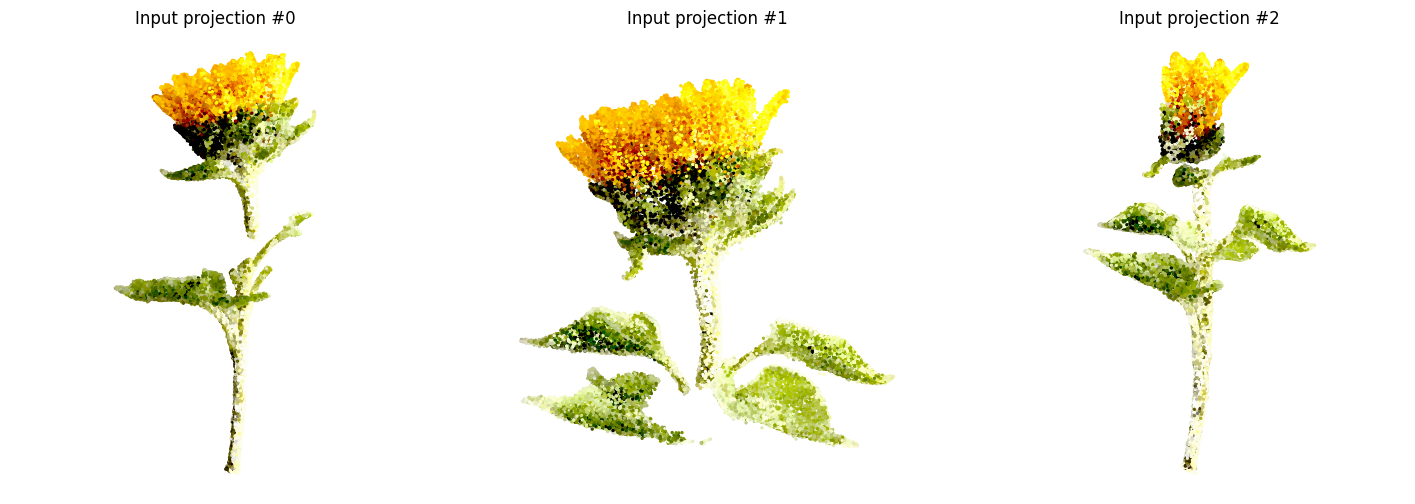

In [5]:
import torch
import matplotlib.pylab as plt

projections = torch.load('data.pth')
rgbs = torch.load('rgbs.pth')

fig, axes = plt.subplots(1, 3, figsize=(18,6))
for n_camera, (d, ax) in enumerate(zip(projections, axes.flatten())):
    xs, ys = d['coordinates'].T
    indices = d['ids']
    ax.scatter(xs, ys, c=rgbs[indices], s=2.)
    ax.axis('equal')
    ax.axis('off')
    ax.set_title(f'Input projection #{n_camera}')

Каждая проекция получена с неизвестного ракурса с помощью пинхол камеры с фокусным расстоянием 50мм, матрица внутренних параметров имеет следующий вид:

```python
# параметры объектива указывают в миллиметрах, а размер сенсора соответствет ширине кадра плёнки
f = 50
sensor_size = 36
# по ним строим матрицу внутренних параметров
K = torch.tensor([
    [2 * f / sensor_size, 0.0, 0.0],
    [0.0, 2 * f / sensor_size, 0.0],
    [0.0,                 0.0, 1.0]
])
```

Каждая проекция задана словарём. Поле `ids` содержит массив с номерами точек в исходном облаке (по ним можно найти соответствия между парой ракурсов), а поле `coordinates` неоднородные координаты в плоскости сенсора. Каждая точка видна как минимум с двух ракурсов.

```python
projection_example = {
    'ids': torch.tensor([0, 1, 2], dtype=torch.int64),
    'coordinates': torch.tensor([[0.1, 0.2], [0.2, 0.3], [0.3, 0.4]], dtype=torch.float32)
}
```

# Формат решения

Решение должно состоять из двух компонент:
1. Массив с реконструкцией исходного трёхмерного облака точек,
2. Отчёт в формате (PDF/Jupyter/Python/Markdown), с подробным описанием вашего метода и его реализацией.

## Облако точек

*Массив* будет использован для автоматизации проверки, но оценка за задание будет определяться в первую очередь на основе отчёта.
Ожидаемый формат массива - тензор размера $(N, 3)$.
```python
solution_example = torch.tensor([[0.1, 0.2, 0.0], [0.2, 0.3, 0.0], [0.3, 0.4, 0.0]], dtype=torch.float32)
```
Масштаб облака точек должен быть выбран исходя из предположения, что расстояние между первой и второй камерой равно *(условной)* единице.

## Отчёт

Вы свободны выбирать свой путь решения, но присланное решение не должно опираться на внешние реализации алгоритмов поиска фундаментальной матрицы, PnP, триангуляции и подобных. Иными словами, решение может использовать методы из библиотек torch`/`numpy, а более сложные алгоритмы должны быть реализованы внутри.

Для отладки и упрощения проверки рекомендуем включить в отчёт визуализации и тесты промежуточных шагов с пояснениями. Также полезной может оказаться визуализация облака точек:
```python
import open3d as o3d
pcd = o3d.geometry.PointCloud()
pcd.points = o3d.utility.Vector3dVector(points)
pcd.colors = o3d.utility.Vector3dVector(colors)
o3d.visualization.draw_geometries([pcd])
```

In [6]:
pip install open3d

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 447.7/447.7 MB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 111.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 101.7/101.7 kB 9.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 139.8/139.8 kB 14.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.0/228.0 kB 17.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 82.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 67.3 MB/s eta 0:00:00
  Attempting uninstall: widgetsnbextension
    Found existing installation: widgetsnbextension 3.6.10
    Uninstalling widgetsnbextension-3.6.10:
      Successfully uninstalled widgetsnbextension-3.6.10
  Attempting uninstall: werkzeug
    Found existing installation: Werkzeug 3.1.3
    Uninstalling Werkzeug-3.1.3:
      Successfully uninstalled Werkzeug-3.1.3
  Attempting uninstall: flask
    Found existing installation: Flask 3.1.1
    Unin


# Решение

Общая идея: сначала построить 3d изображения по парам проекций, затем объединить их в одно. Для восстановления 3d картинки будем делать следующее

- для пары проекций ищем общие точки по id
- переводим координаты из проекций в однородные
- ищем фундаментальную матрицу с помощью кода с семинара
- по фундаментальной матрице F находим essential matrix E
- из Е восстанавливаем t, R (я это делаю с помощью SVD, как говорилось на лекции, формулы взяла [отсюда](https://en.wikipedia.org/wiki/Essential_matrix))
- далее по R, t считаем матрицы проекции (точнее, только $H_r$, так как для $H_l $ нужна только K).

- затем восстанавливаем 3d точки для каждой пары, решая SVD, как на семинаре 1





In [7]:
import numpy as np
import torch
import matplotlib.pylab as plt
from tqdm import tqdm
import open3d as o3d

матрица внутренних параметров

In [9]:
# параметры объектива указывают в миллиметрах, а размер сенсора соответствет ширине кадра плёнки
f = 50
sensor_size = 36
# по ним строим матрицу внутренних параметров (intrinsic parameters)
K = torch.tensor([
    [2 * f / sensor_size, 0.0, 0.0],
    [0.0, 2 * f / sensor_size, 0.0],
    [0.0,                 0.0, 1.0]
])

Для начала надо уметь переводить координаты в однородные и обратно(код с семинара):

In [4]:
def homogenize_points(points):
    last_coordinate = torch.ones_like(points[..., -1:])
    return torch.cat((points, last_coordinate), dim=-1)

In [10]:
def dehomogenize_points(points):
    return points[..., :-1] / (points[..., -1:] + 1e-8 * torch.sign(points[..., -1:]))

Восстановим матрицу F (тоже код с семинара)

In [8]:
def get_fundamental_matrix(points_l, points_r):
    #raise NotImplementedError
    equations = torch.einsum('bi,bj->bij', points_r, points_l).view(-1, 9)
    u, s, v = torch.linalg.svd(equations)
    F = v[-1].view(3, 3)
    return F

def compute_residuals(F, points_l, points_r):
    #raise NotImplementedError
    return torch.einsum('bi,ij,bj->b', points_r, F, points_l)

def compute_errors(F, points_l, points_r):
    # optional
    raise NotImplementedError

Функции для нахождения общих точек по двум проекциям - они возвращают данные в разных форматах

In [11]:
def get_common_coords(proj_0, proj_1):
    ids0, coords0 = proj_0['ids'], proj_0['coordinates']
    ids1, coords1 = proj_1['ids'], proj_1['coordinates']

    common_ids = torch.tensor(list(set(ids0.tolist()) & set(ids1.tolist())))

    idx0 = torch.nonzero(torch.isin(ids0, common_ids)).squeeze(1)
    idx1 = torch.nonzero(torch.isin(ids1, common_ids)).squeeze(1)

    return coords0[idx0], coords1[idx1], common_ids

In [12]:
def get_common_projections(proj_a, proj_b):
    ids_a, coords_a = proj_a['ids'], proj_a['coordinates']
    ids_b, coords_b = proj_b['ids'], proj_b['coordinates']

    # словари для быстрого доступа
    map_a = {idx.item(): i for i, idx in enumerate(ids_a)}
    map_b = {idx.item(): i for i, idx in enumerate(ids_b)}

    common_ids = list(set(map_a.keys()) & set(map_b.keys()))

    indices_a = torch.tensor([map_a[idx] for idx in common_ids])
    indices_b = torch.tensor([map_b[idx] for idx in common_ids])

    common_coords_a = coords_a[indices_a]
    common_coords_b = coords_b[indices_b]

    return {
        'ids': torch.tensor(common_ids),
        'coordinates_a': common_coords_a,
        'coordinates_b': common_coords_b
    }

Функция для восстановления essential matrix E по матрице F.
На лекции было, что $F=K^{-T} [t]_x R K^{-1} ⇒ E = [t]_x R = K^T F K$ - несложно посчитать.

In [13]:
def get_essential_matrix(F):
    E = K.T @ F @ K
    return E

Теперь из E можно с помощью SVD получить rotation matrix R, translation t: $E = [t]_x R$

SVD для E: $E = U \Sigma V^T$, тогда $[t]_x = UWΣ U^T, R = UW^{-1} V^T$, где W = [[0, -1, 0], [1, 0, 0], [0, 0, 1]] и $W^{-1}=W^T$

Заметим, что $[t]_xR=U\Sigma V^T=E$

При этом нам нужен вектор t, а не матричное представление на вектор t, поэтому в функции я также вычисляю вектор t по матрице t_x.

In [14]:
def get_rotation_translation(E, is_last=0):
    U, S, Vt = torch.linalg.svd(E, full_matrices=True)

    W = [[0, -1, 0],
        [1, 0, 0],
        [0, 0, 1]]

    W = torch.tensor(W)

    W = W.float()
    S = S.float()
    t_x = U @ W @ torch.diag(S) @ U.T
    t = torch.tensor([[(t_x[2, 1] - t_x[1, 2]) / 2,
                     (t_x[0, 2] - t_x[2, 0]) / 2,
                     (t_x[1, 0] - t_x[0, 1]) / 2]]).T


    if is_last==0:
        R = U @ W @ Vt
    else:
        R = U @ W.T @ Vt

    return t, R

Считаем матрицы проекции - $H_l, H_r$

На лекции было
$\quad H_l = [K | 0] \begin{pmatrix} I & 0 \\ 0 & 1\end{pmatrix} = M_{int} \begin{pmatrix} I & 0 \\ 0 & 1\end{pmatrix} $
$\quad H_r = [K | 0] \begin{pmatrix} R & t \\ 0 & 1\end{pmatrix} = M_{int} \begin{pmatrix} R & t \\ 0 & 1\end{pmatrix}$

при этом внутренние параметры камеры К у нас одни и те же. Для каждой пары проекций первая будет соответствовать $H_l$, а для второй буду считать поворот и сдвиг и вычислять $H_r$

In [15]:
def get_proj_matrix(t_x, R):
    zero_col = torch.zeros(K.shape[0], 1)
    M_int = torch.cat([K, zero_col], dim=1)
    ones = torch.eye(4)
    H_l = M_int @ ones
    # делаю столбец [t, 1]
    new_element = torch.tensor([1.0]).unsqueeze(1)
    #print('NEW_el shape', new_element.shape)
    t_x_1 = torch.cat((t_x, new_element), dim=0)
    zero_row = zero_col.T
    R_0 = torch.cat([R, zero_row], dim=0)
    #print('SHAPES', R_0.shape, t_x_1.shape)
    full = torch.cat([R_0, t_x_1], dim=1)
    H_r = H @ full
    return H_l, H_r

Функция для триангуляции - восстанавливаем координаты по двум 2d изображениям. Тут запрогано то, что происходило на 1 семинаре, когда Мишан объяснял DLT. Решаем систему BP (в терминах семинара) = AX = 0 через SVD и берём последний столбец, соответствующий минимальному сингулярному значению

In [17]:
def linear_triangulation(Hl, Hr, xl, xr):
    # Строим систему уравнений AX = 0
    A = [
        xl[0] * Hl[2] - Hl[0],
        xl[1] * Hl[2] - Hl[1],
        xr[0] * Hr[2] - Hr[0],
        xr[1] * Hr[2] - Hr[1]
    ]
    A = torch.stack(A)

    # Решаем через SVD
    _, _, Vt = torch.linalg.svd(A)
    X = Vt[-1]  # Последняя строка V^T
    return X # Возвращаем (X, Y, Z)

Объединим все функции в полноценный пайплайн для получения точек по двум проекциям

In [16]:
def full_pipeline(proj_one, proj_two):
    coords0, coords1, common_01 = get_common_coords(proj_one, proj_two)

    colours = rgbs[common_01]

    hom_coords0_1 = homogenize_points(coords1)
    hom_coords1_0 = homogenize_points(coords0)
    F = get_fundamental_matrix(hom_coords0_1, hom_coords1_0)
    E = get_essential_matrix(F)
    t_x, R = get_rotation_translation(E)
    H_l, H_r = get_proj_matrix(t_x, R)
    points = []
    for i in tqdm(range(len(hom_coords0_1))):
        points.append(linear_triangulation(H_l, H_r,hom_coords0_1[i], hom_coords1_0[i])) #hom_coords0_1[i], hom_coords1_0[i]))
    points = torch.stack(points)
    points = dehomogenize_points(points)
    return {'ids': torch.as_tensor(common_01), 'coordinates': torch.as_tensor(np.asarray(points))}

получаем три облака точек

In [18]:
points_01 = full_pipeline(projections[1], projections[0])
points_02 = full_pipeline(projections[0], projections[2])
points_12 = full_pipeline(projections[1], projections[2])

100%|██████████| 40500/40500 [00:06<00:00, 6215.86it/s]


Так как в колабе у меня не работает визуализация, прикрепляю то, что получилось у меня для всех пар проекций

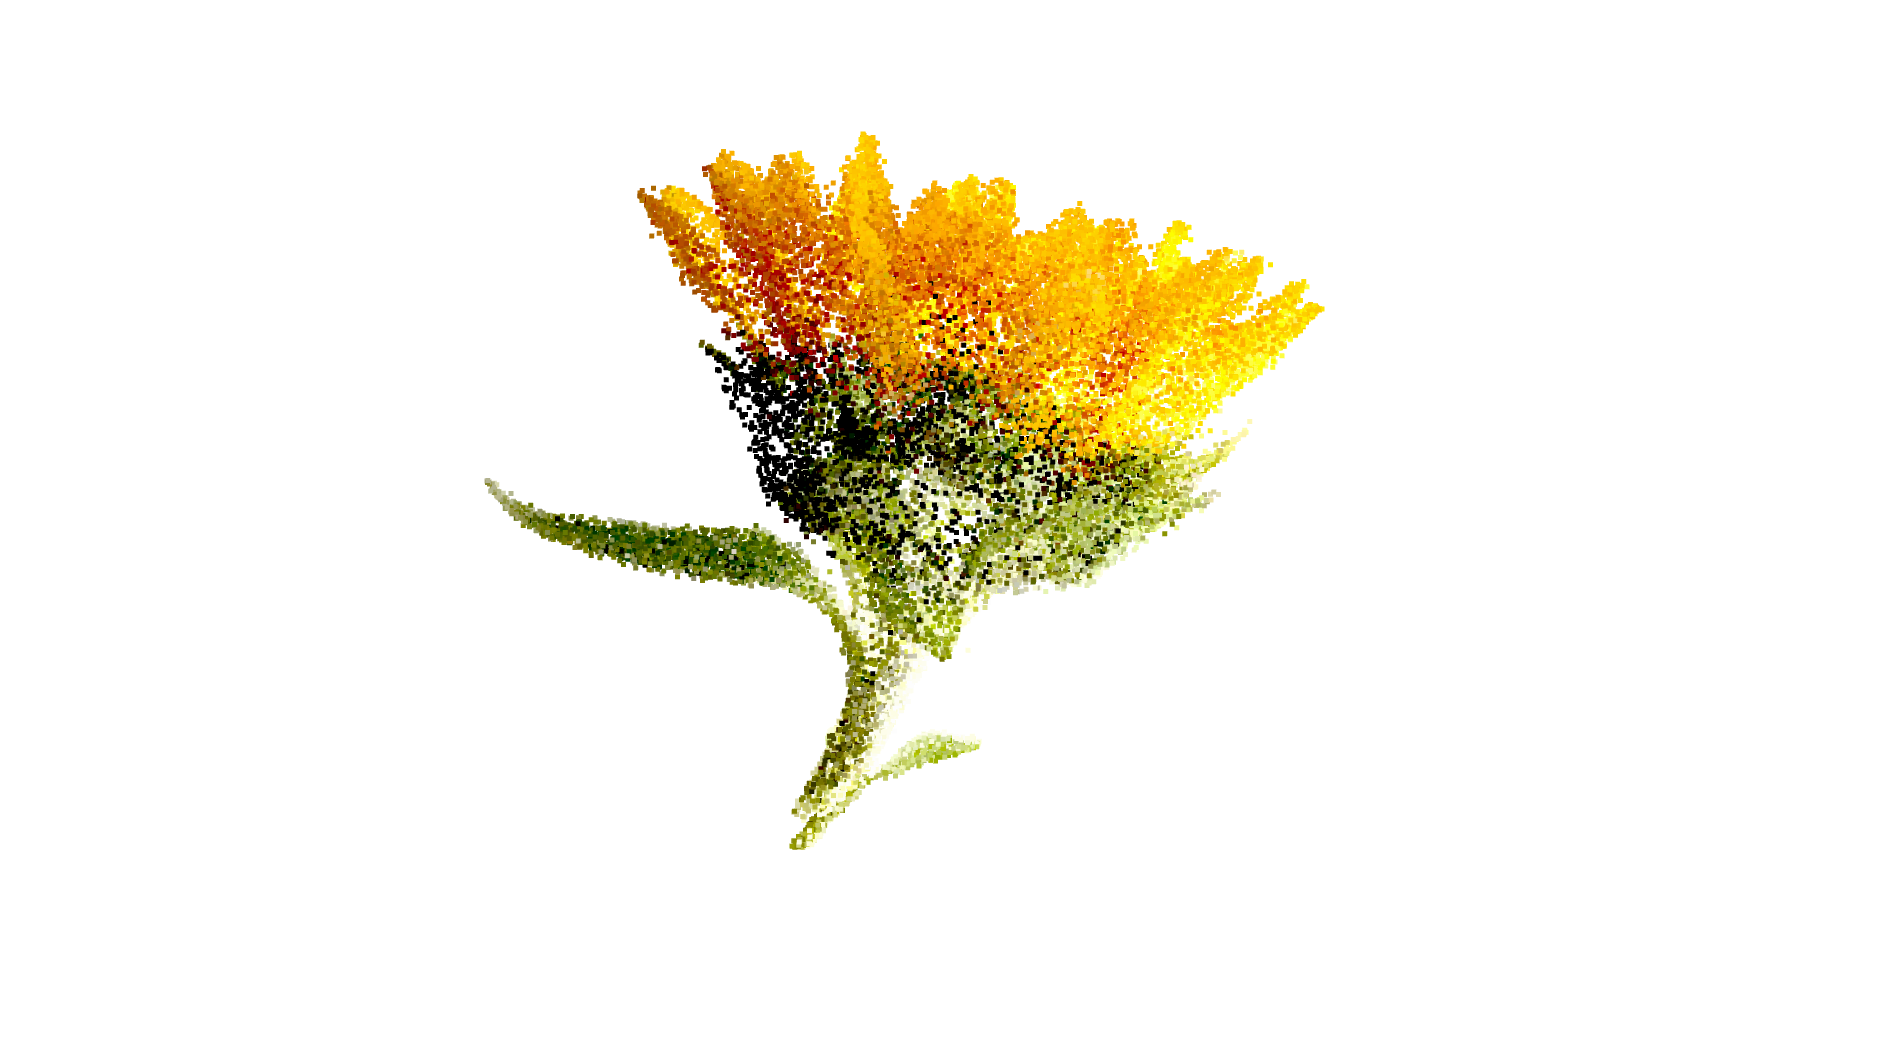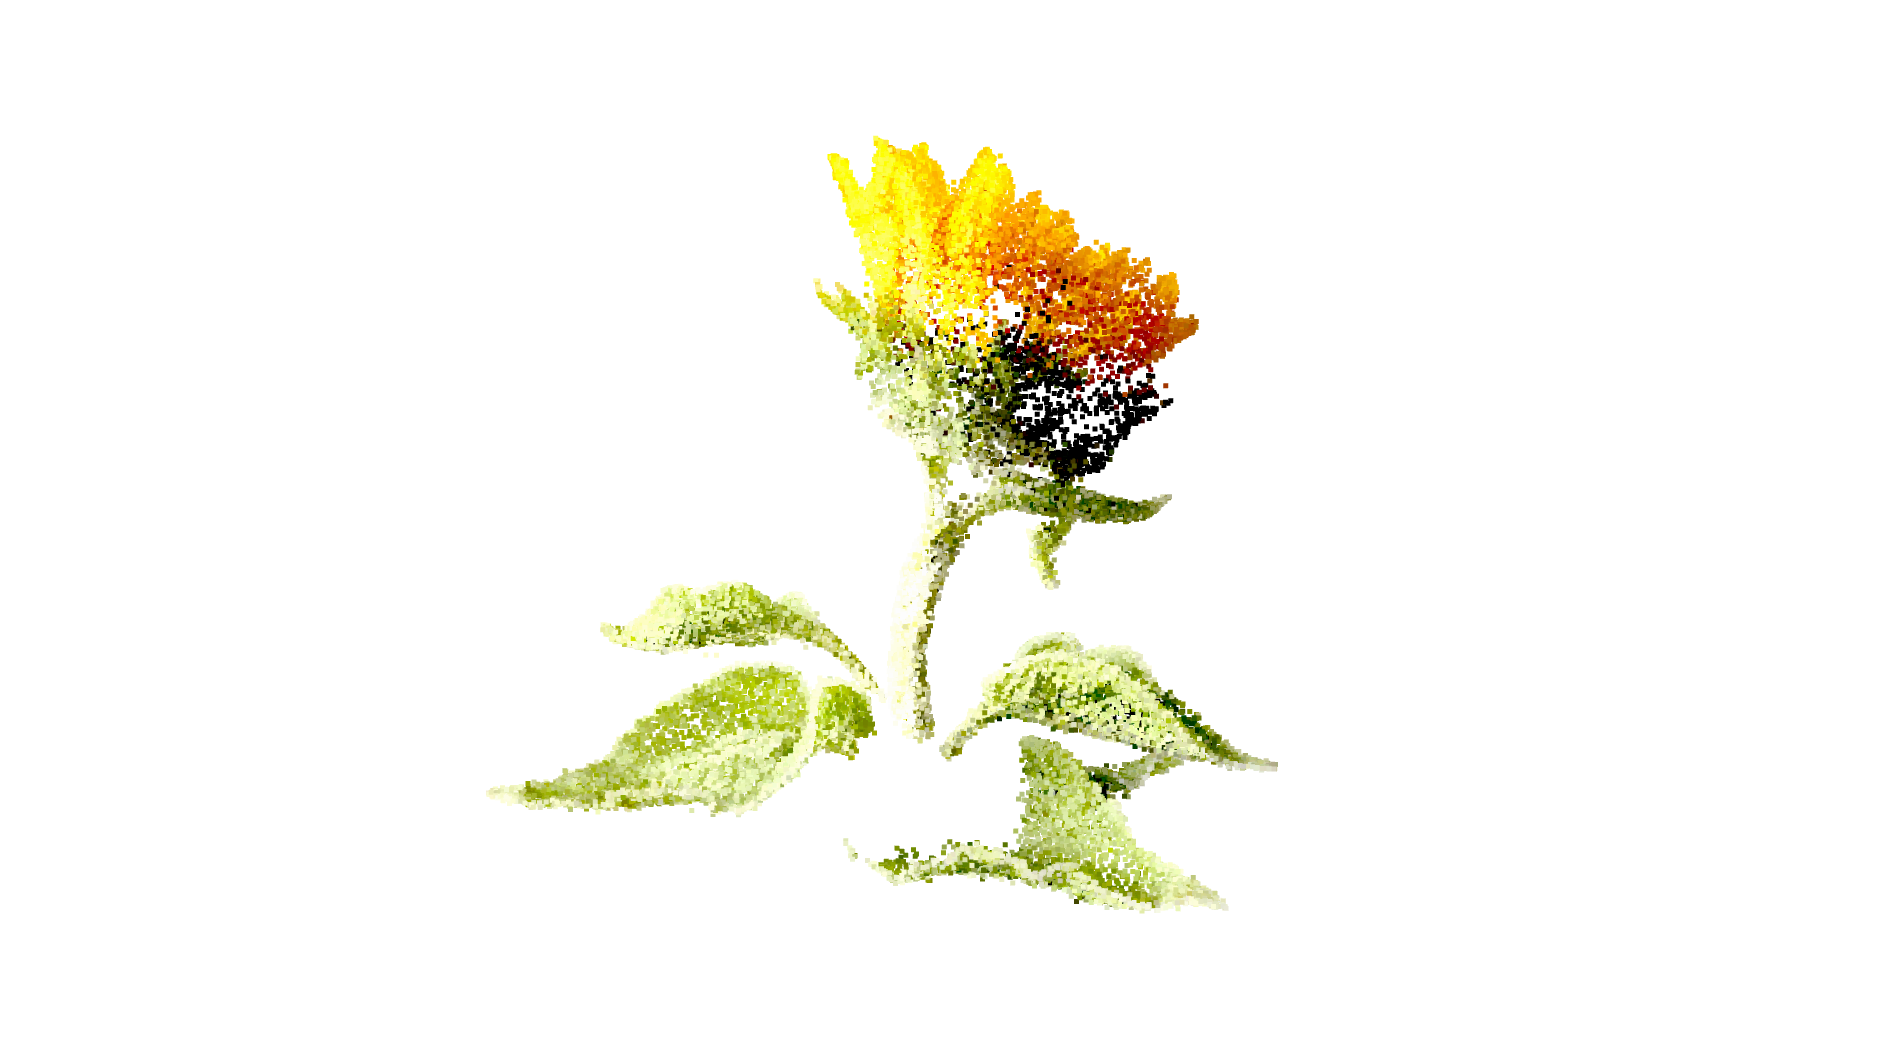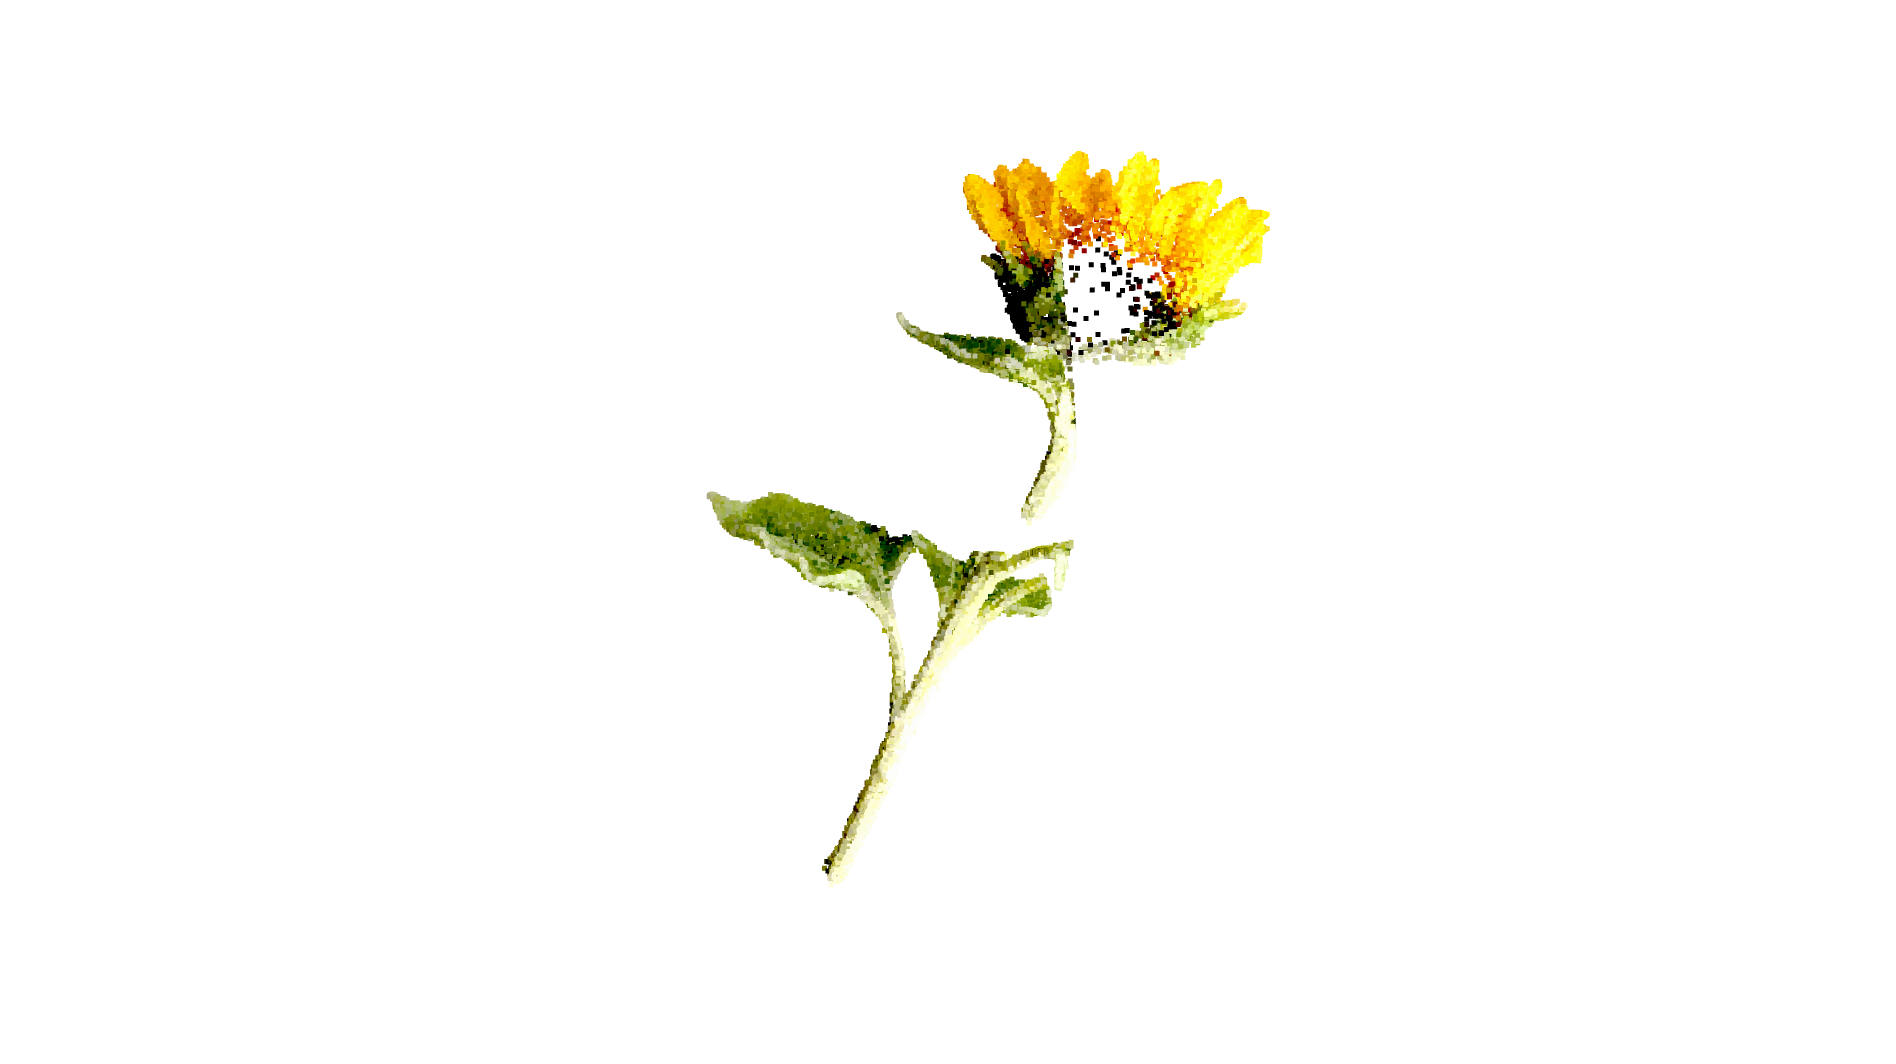

(скриншоты 3d изображений, их можно получить, запустив final.py)

Осталось объединить три облака точек в одно - для этого проделаем следующее:

Для двух облаков точек сначала найдём общие точки. Затем надо найти преобразование из одной системы координат (A), соответствующей первому облаку, в другую систему координат (B) (у меня это матрица transform).

Определяем маску для точек из первого облака, которых нет во втором и преобразуем уникальные точки первого облака в систему координат камеры B.

In [20]:
def merge_point_clouds(cloud_a, cloud_b):
    # общие точки между двумя облаками
    overlap = get_common_projections(cloud_a, cloud_b)
    shared_ids = overlap['ids']
    points_a = homogenize_points(overlap['coordinates_a'])
    points_b = homogenize_points(overlap['coordinates_b'])

    transform = torch.linalg.pinv(points_a) @ points_b

    shared_id_set = set(shared_ids.tolist())
    unique_mask = torch.tensor([idx.item() not in shared_id_set for idx in cloud_a['ids']])

    transformed_coords = dehomogenize_points(homogenize_points(cloud_a['coordinates']) @ transform)

    merged_coords = torch.cat([transformed_coords[unique_mask], cloud_b['coordinates']], dim=0)
    merged_ids = torch.cat([cloud_a['ids'][unique_mask], cloud_b['ids']], dim=0)

    return {'ids': merged_ids, 'coordinates': merged_coords}

In [21]:
intersection1 = merge_point_clouds(points_01, points_02)
intersection2 = merge_point_clouds(intersection1, points_12)

код для визуализации

In [22]:
pcd = o3d.geometry.PointCloud()
pcd.points = o3d.utility.Vector3dVector(intersection2['coordinates'])
colours = rgbs[intersection2['ids']]
pcd.colors = o3d.utility.Vector3dVector(colours)
o3d.visualization.draw_geometries([pcd])


[Open3D WARNING] GLFW Error: Failed to detect any supported platform
[Open3D WARNING] GLFW initialized for headless rendering.
[Open3D WARNING] GLFW Error: OSMesa: Library not found
[Open3D WARNING] Failed to create window
[Open3D WARNING] [DrawGeometries] Failed creating OpenGL window.


И вот так выглядит финальный результат
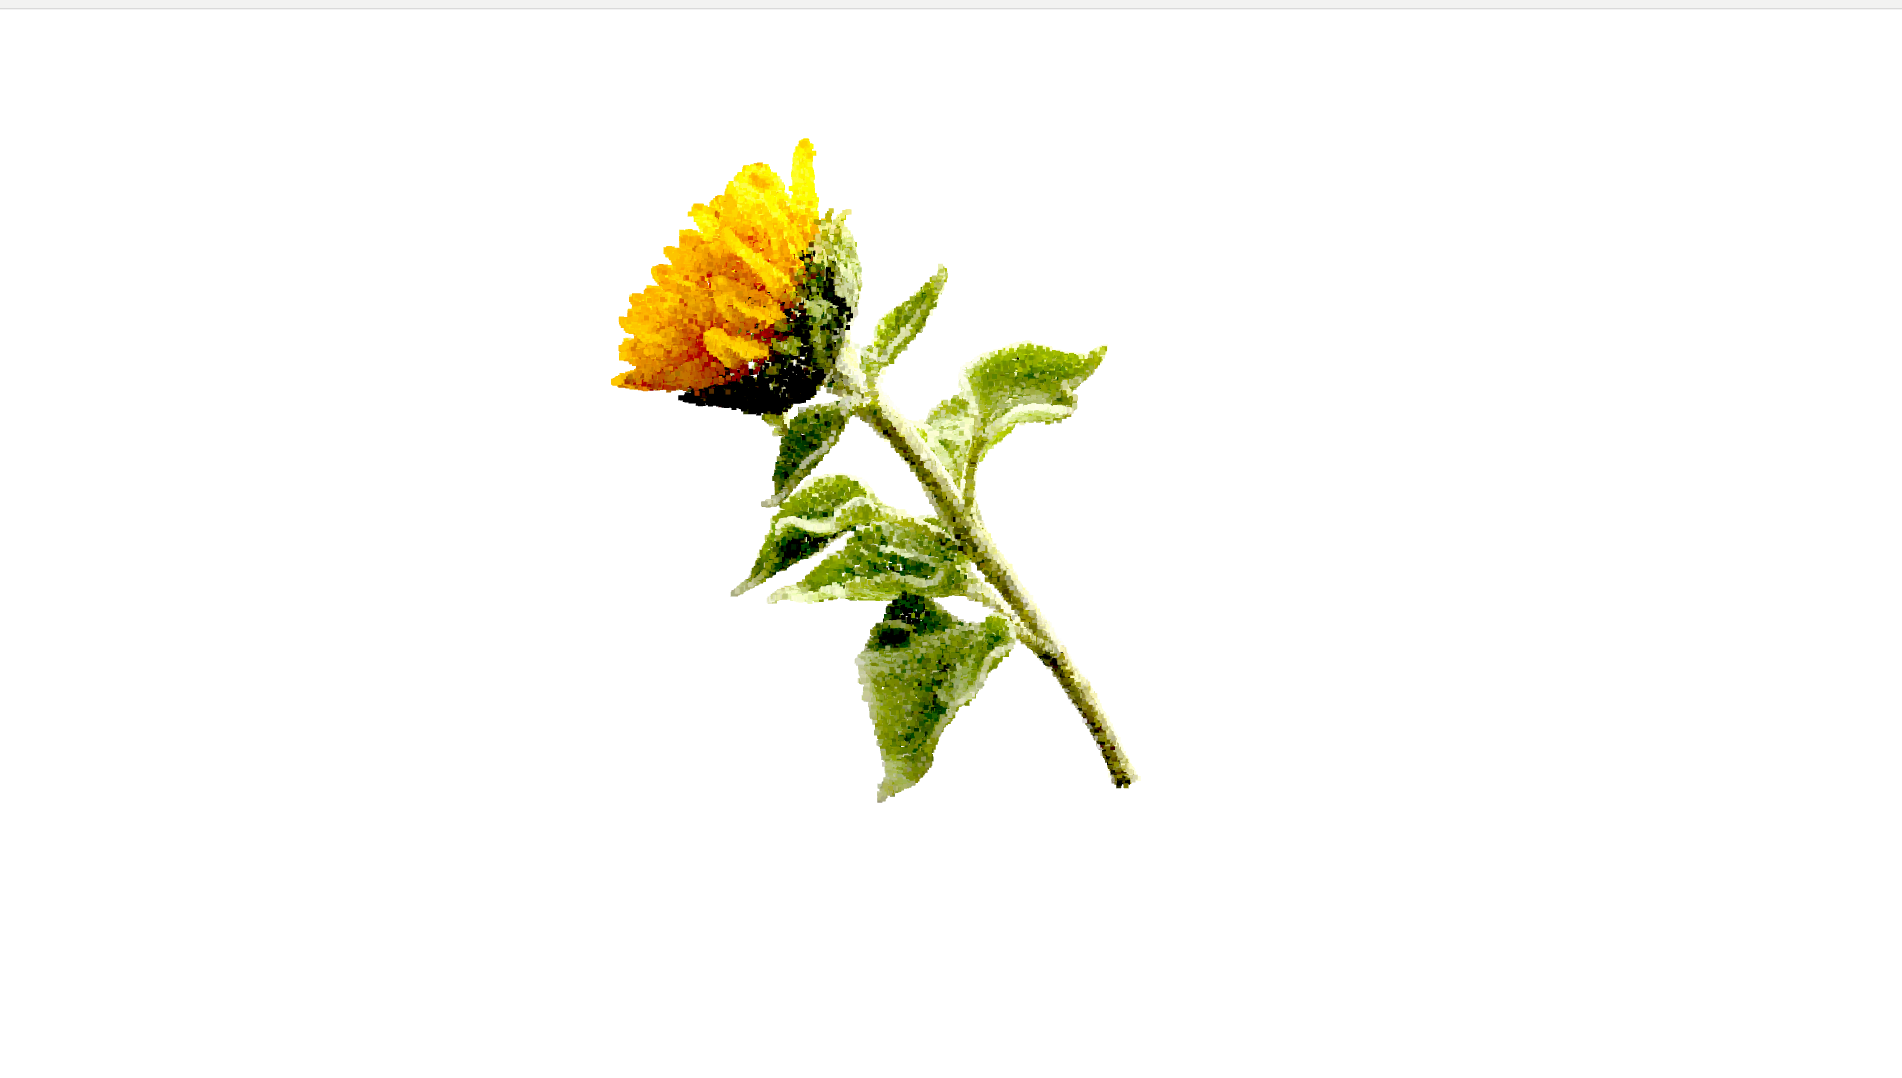

вайб у дз такой

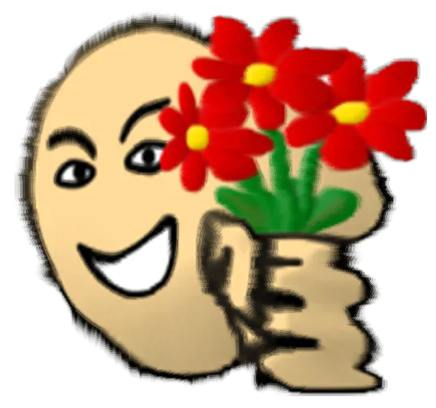